# 06 — Stacking với AdaBoost

Dùng bộ ba được chọn ở notebook 05 để tạo đặc trưng OOF và huấn luyện AdaBoost tầng cuối. So sánh với các mô hình đơn, soft voting và weighted soft voting. Chỉ dùng nhóm `selected_models`, không khảo sát lại top 3 bộ ba.

## 1. Import và cấu hình

Nạp thư viện, đặt 10 fold và thư mục kết quả `results/stacking_adaboost/`. Seed được lấy từ 05 ở bước sau. Cache mặc định tắt; bật `USE_CACHE` để tái sử dụng kết quả khi đầu vào không đổi.

In [1]:
from pathlib import Path
import sys, time, json, inspect, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from joblib import Memory, dump, load
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, ConfusionMatrixDisplay

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import load_prepared_mnist

SEED, N_FOLDS, USE_CACHE = 42, 5, False
CLASSES = np.arange(10)
OUTPUT = ROOT / 'results' / 'stacking_adaboost'
OUTPUT.mkdir(parents=True, exist_ok=True)
memory = Memory(OUTPUT / 'cache' if USE_CACHE else None, verbose=0)
selection_dir = ROOT / 'results' / 'select_base_models'

## 2. Nạp nhóm mô hình đã chọn

Đọc `selection.json`, cấu hình estimator và split do 05 lưu; nếu thiếu split, tái tạo bằng seed và stratify. Loader trả về 4 giá trị. Kiểm tra cấu hình và dấu vân tay train/validation trước khi huấn luyện; giữ test riêng cho đánh giá cuối.

In [2]:
selection = json.loads((selection_dir / 'selection.json').read_text(encoding='utf-8'))
SEED = int(selection['seed'])
names = selection['selected_models']
estimator_file = selection_dir / 'all_estimators.joblib'
estimators = load(estimator_file if estimator_file.exists() else selection_dir / 'selected_estimators.joblib')
base_models = {name: clone(estimators[name]) for name in names}
assert len(names) == 3 and len(set(names)) == 3

X, y, X_test, y_test = load_prepared_mnist()
X, y = np.asarray(X, dtype=np.float32), np.asarray(y, dtype=int)
X_test, y_test = np.asarray(X_test, dtype=np.float32), np.asarray(y_test, dtype=int)
split_file = selection_dir / 'split_indices.npz'
if split_file.exists():
    with np.load(split_file) as indices:
        tr, va = indices['train_idx'], indices['val_idx']
else:
    n_val = selection['data_fingerprint']['y_val']['shape'][0]
    tr, va = train_test_split(np.arange(len(y)), test_size=n_val, stratify=y, random_state=SEED)
assert not np.intersect1d(tr, va).size
X_train, y_train, X_val, y_val = X[tr], y[tr], X[va], y[va]

def array_fingerprint(array):
    a = np.ascontiguousarray(array)
    return dict(shape=list(a.shape), dtype=str(a.dtype),
                sha256=hashlib.sha256(memoryview(a).cast('B')).hexdigest())

data_fingerprint = {name: array_fingerprint(array) for name, array in
    dict(X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val).items()}
assert data_fingerprint == selection['data_fingerprint'], 'Dữ liệu/split khác notebook 05; kiểm tra loader và chạy lại 05.'
# Tránh dùng nhầm estimator từ một lượt chạy khác.
for name in names:
    expected = selection['all_params'][name]
    actual = json.loads(json.dumps(base_models[name].get_params(), default=str))
    assert actual == expected, f'Cấu hình {name} khác selection.json; chạy lại ô lưu của 05.'
del X
print('Bộ ba từ 05:', names)
print('Train:', X_train.shape, 'Validation:', X_val.shape, 'Test:', X_test.shape)
display(pd.DataFrame({'model': names, 'config': [str(base_models[name]) for name in names]}))

Bộ ba từ 05: ['SVM', 'KNN', 'MLP256_128']
Train: (50000, 784) Validation: (10000, 784) Test: (10000, 784)


,model,config
0,SVM,"SVC(C=10, cache_size=1000, probability=True, r..."
1,KNN,"KNeighborsClassifier(n_jobs=-1, n_neighbors=3,..."
2,MLP256_128,"MLPClassifier(alpha=0.01, batch_size=256, hidd..."


## 3. Tạo đặc trưng OOF 5-fold

Mỗi ảnh train nhận xác suất từ mô hình học trên 4 fold còn lại. Ghép 3 mô hình × 10 lớp thành 30 đặc trưng; kiểm tra mỗi ảnh thuộc đúng một fold holdout. AdaBoost học trên đặc trưng OOF.

In [3]:
@memory.cache
def fold_proba(estimator, X_fit, y_fit, X_holdout):
    start = time.perf_counter()
    model = clone(estimator).fit(X_fit, y_fit)
    fit_s = time.perf_counter() - start
    assert np.array_equal(model.classes_, CLASSES)
    proba = model.predict_proba(X_holdout)
    return proba, fit_s, time.perf_counter() - start

folds = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(X_train, y_train))
seen, fold_id = np.zeros(len(y_train), dtype=int), np.zeros(len(y_train), dtype=int)
for k, (_, hold) in enumerate(folds):
    seen[hold] += 1
    fold_id[hold] = k
assert np.all(seen == 1)
Z_train = np.zeros((len(y_train), len(CLASSES) * len(names)), dtype=np.float32)
oof_rows = []
start = time.perf_counter()
for j, name in enumerate(names):
    for k, (fit, hold) in enumerate(folds, 1):
        proba, fit_s, fold_s = fold_proba(base_models[name], X_train[fit], y_train[fit], X_train[hold])
        Z_train[hold, len(CLASSES)*j:len(CLASSES)*(j+1)] = proba
        oof_rows.append(dict(model=name, fold=k, recorded_fit_seconds=fit_s, recorded_fold_seconds=fold_s))
        print(f'{name}: fold {k}/{N_FOLDS}', flush=True)
oof_wall_s = time.perf_counter() - start
oof_times = pd.DataFrame(oof_rows)
print('OOF:', Z_train.shape)

d:\Nhận dạng mẫu\mnist\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM: fold 1/5


d:\Nhận dạng mẫu\mnist\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM: fold 2/5


d:\Nhận dạng mẫu\mnist\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM: fold 3/5


... (9 outputs left out)

MLP256_128: fold 4/5


d:\Nhận dạng mẫu\mnist\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP256_128: fold 5/5
OOF: (50000, 30)


d:\Nhận dạng mẫu\mnist\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


## 4. Refit và tạo đặc trưng validation

Refit từng mô hình trên toàn bộ train, ghép xác suất theo đúng thứ tự mô hình và lớp 0–9. Mô hình đơn dùng argmax xác suất. Chọn mô hình đơn tốt nhất trong bộ ba theo accuracy validation, F1 macro, tên.

In [4]:
@memory.cache
def fit_base(estimator, X, y):
    start = time.perf_counter()
    model = clone(estimator).fit(X, y)
    return model, time.perf_counter() - start

def predict_bases(X):
    probabilities, predictions, rows = {}, {}, []
    for name in names:
        model = fitted[name]
        assert np.array_equal(model.classes_, CLASSES)
        start = time.perf_counter()
        probabilities[name] = model.predict_proba(X)
        proba_s = time.perf_counter() - start
        start = time.perf_counter()
        predictions[name] = probabilities[name].argmax(1)
        label_s = time.perf_counter() - start
        rows.append(dict(model=name, proba_seconds=proba_s, predict_seconds=proba_s + label_s))
    return probabilities, predictions, rows

fitted, base_rows = {}, []
start = time.perf_counter()
for name in names:
    fitted[name], fit_s = fit_base(base_models[name], X_train, y_train)
    base_rows.append(dict(model=name, recorded_fit_seconds=fit_s))
refit_wall_s = time.perf_counter() - start
base_times = pd.DataFrame(base_rows)
val_proba, val_pred, val_times = predict_bases(X_val)
Z_val = np.concatenate([val_proba[name] for name in names], axis=1)
voting_acc = accuracy_score(y_val, np.mean([val_proba[name] for name in names], axis=0).argmax(1))

# Chọn model đơn trước khi xem test: accuracy, rồi F1 macro validation.
single_val = pd.DataFrame([
    dict(model=name, accuracy=accuracy_score(y_val, val_pred[name]),
         f1_macro=precision_recall_fscore_support(y_val, val_pred[name], average='macro', zero_division=0)[2])
    for name in names])
best_single_name = single_val.sort_values(['accuracy', 'f1_macro', 'model'], ascending=[False, False, True]).iloc[0]['model']
print('Model đơn tốt nhất trong bộ 3 model chọn trên validation:', best_single_name)

d:\Nhận dạng mẫu\mnist\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
d:\Nhận dạng mẫu\mnist\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


Model đơn tốt nhất trong bộ 3 model chọn trên validation: SVM


## 5. Khảo sát weighted soft voting

Tái sử dụng xác suất để thử 7 cấu hình: trọng số đều và lần lượt tăng mỗi thành viên lên 2 hoặc 3. Chọn theo accuracy validation, F1 macro phá hòa; nếu vẫn hòa giữ cấu hình đứng trước. Chốt trọng số trước khi đánh giá test.

,SVM,KNN,MLP256_128,accuracy,f1_macro
0,0.33333,0.33333,0.33333,0.9852,0.98515
1,0.50000,0.25000,0.25000,0.9851,0.98505
2,0.25000,0.50000,0.25000,0.9817,0.98170
3,0.25000,0.25000,0.50000,0.9845,0.98442
4,0.60000,0.20000,0.20000,0.9845,0.98444
5,0.20000,0.60000,0.20000,0.9812,0.98120
6,0.20000,0.20000,0.60000,0.9844,0.98433


Trọng số đã chốt: {'SVM': np.float64(0.3333), 'KNN': np.float64(0.3333), 'MLP256_128': np.float64(0.3333)}
Chênh lệch accuracy validation so với soft voting: +0.000 điểm phần trăm
Khảo sát chưa cho thấy lợi ích của trọng số không đều; giữ trung bình đều.


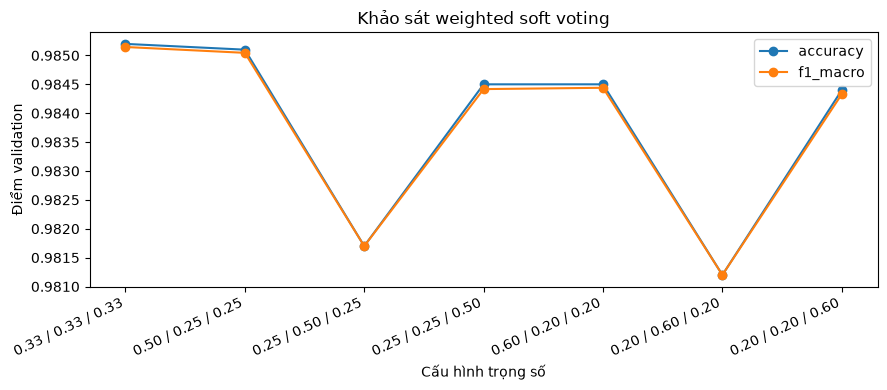

In [5]:
weight_grid = np.array([[1, 1, 1], [2, 1, 1], [1, 2, 1], [1, 1, 2],
                        [3, 1, 1], [1, 3, 1], [1, 1, 3]], dtype=float)
weight_grid /= weight_grid.sum(axis=1, keepdims=True)
weight_rows = []
start = time.perf_counter()
for weights in weight_grid:
    pred = np.average([val_proba[name] for name in names], axis=0, weights=weights).argmax(1)
    _, _, f1, _ = precision_recall_fscore_support(y_val, pred, labels=CLASSES, average='macro', zero_division=0)
    weight_rows.append({**dict(zip(names, weights)), 'accuracy': accuracy_score(y_val, pred), 'f1_macro': f1})
weight_search_s = time.perf_counter() - start
weight_results = pd.DataFrame(weight_rows)
best_weight_index = int(weight_results.sort_values(['accuracy', 'f1_macro'], ascending=False, kind='stable').index[0])
voting_weights = weight_grid[best_weight_index].copy()
display(weight_results.round(5))
print('Trọng số đã chốt:', dict(zip(names, voting_weights.round(4))))
gain = (
    float(weight_results.loc[best_weight_index, 'accuracy'])
    - float(weight_results.loc[0, 'accuracy'])
)
print(f'Chênh lệch accuracy validation so với soft voting: {gain*100:+.3f} điểm phần trăm')
if best_weight_index == 0:
    print('Khảo sát chưa cho thấy lợi ích của trọng số không đều; giữ trung bình đều.')

ax = weight_results[['accuracy', 'f1_macro']].plot(marker='o', figsize=(9, 4))
ax.set(xticks=range(len(weight_grid)), xlabel='Cấu hình trọng số', ylabel='Điểm validation',
       title='Khảo sát weighted soft voting')
ax.set_xticklabels([' / '.join(f'{w:.2f}' for w in weights) for weights in weight_grid], rotation=25, ha='right')
ax.figure.tight_layout(); ax.figure.savefig(OUTPUT / 'weighted_voting_search.png', dpi=300); plt.show()

## 6. Khảo sát AdaBoost tầng cuối

Fit trên OOF và chấm trên validation. Thay từng tham số quanh baseline `(learning_rate=0.5, max_depth=2, n_estimators=100)`, không duyệt mọi tổ hợp. Dùng AdaBoost SAMME với cây quyết định; đối chiếu với accuracy soft voting.

In [6]:
def make_meta(lr=0.5, depth=2, trees=100):
    params = dict(estimator=DecisionTreeClassifier(max_depth=depth, random_state=SEED),
                  n_estimators=trees, learning_rate=lr, random_state=SEED)
    if 'algorithm' in inspect.signature(AdaBoostClassifier).parameters:
        params['algorithm'] = 'SAMME'
    return AdaBoostClassifier(**params)

def score_row(pred, lr, depth, trees):
    _, _, f1, _ = precision_recall_fscore_support(y_val, pred, average='macro', zero_division=0)
    return dict(learning_rate=lr, max_depth=depth, n_estimators=trees,
                accuracy=accuracy_score(y_val, pred), f1_macro=f1)

def show_results(table, parameter):
    display(table.round(5))
    ax = table.plot(x=parameter, y=['accuracy', 'f1_macro'], marker='o', figsize=(7, 4))
    ax.axhline(voting_acc, color='gray', linestyle='--', label='Soft voting accuracy')
    ax.set(ylabel='Điểm validation', title=f'AdaBoost — {parameter}')
    ax.legend(); ax.grid(alpha=.2)
    ax.figure.tight_layout(); ax.figure.savefig(OUTPUT / f'survey_{parameter}.png', dpi=300)
    plt.show()

meta_search_fit_s = 0.0

### 6.1. Learning rate

Thử 5 giá trị learning rate, giữ độ sâu 2 và 100 cây.

,learning_rate,max_depth,n_estimators,accuracy,f1_macro
0,0.01,2,100,0.7980,0.72447
1,0.10,2,100,0.9834,0.98334
2,0.20,2,100,0.9853,0.98524
3,0.50,2,100,0.9846,0.98454
4,1.00,2,100,0.9823,0.98214


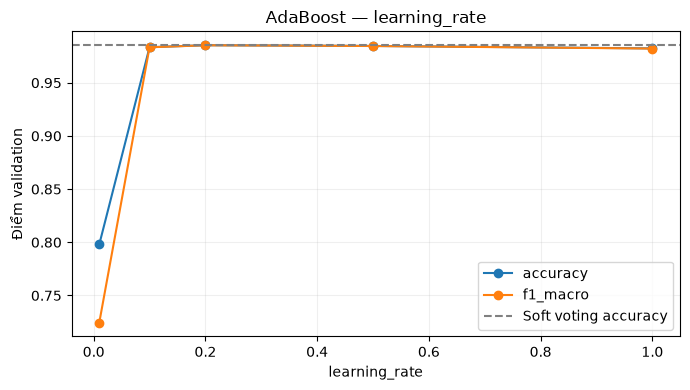

In [7]:
lr_rows = []
for lr in [0.01, 0.1, 0.2, 0.5, 1.0]:
    model = make_meta(lr=lr)
    start = time.perf_counter(); model.fit(Z_train, y_train)
    meta_search_fit_s += time.perf_counter() - start
    lr_rows.append(score_row(model.predict(Z_val), lr, 2, 100))
lr_results = pd.DataFrame(lr_rows)
show_results(lr_results, 'learning_rate')

### 6.2. Độ sâu cây

Thử độ sâu 1–4, giữ learning rate 0,5 và 100 cây; tái sử dụng kết quả baseline.

,learning_rate,max_depth,n_estimators,accuracy,f1_macro
0,0.5,1.0,100.0,0.9844,0.98432
1,0.5,2.0,100.0,0.9846,0.98454
2,0.5,3.0,100.0,0.9848,0.98468
3,0.5,4.0,100.0,0.9827,0.98252


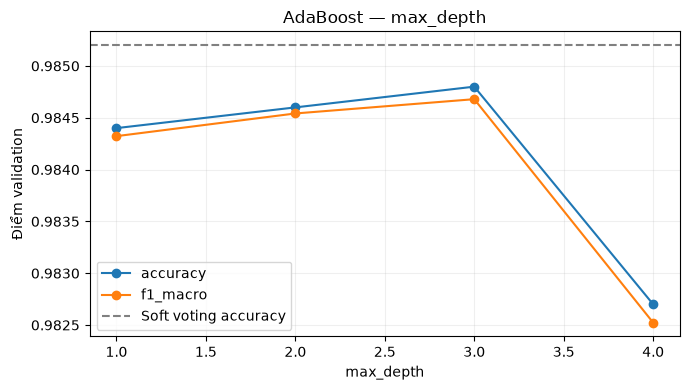

In [8]:
depth_rows = []
for depth in [1, 2, 3, 4]:
    if depth == 2:
        row = lr_results.loc[lr_results.learning_rate == 0.5].iloc[0].to_dict()
    else:
        model = make_meta(depth=depth)
        start = time.perf_counter(); model.fit(Z_train, y_train)
        meta_search_fit_s += time.perf_counter() - start
        row = score_row(model.predict(Z_val), 0.5, depth, 100)
    depth_rows.append(row)
depth_results = pd.DataFrame(depth_rows)
show_results(depth_results, 'max_depth')

### 6.3. Số cây

Fit tối đa 300 cây một lần, lấy các mốc bằng `staged_predict`. Chỉ đánh giá các mốc thực sự đạt được nếu AdaBoost dừng sớm.

,learning_rate,max_depth,n_estimators,accuracy,f1_macro
0,0.5,2,1,0.3152,0.22023
1,0.5,2,20,0.9841,0.98406
2,0.5,2,50,0.9848,0.98472
3,0.5,2,100,0.9846,0.98454
4,0.5,2,200,0.9839,0.98382
5,0.5,2,300,0.9828,0.98269


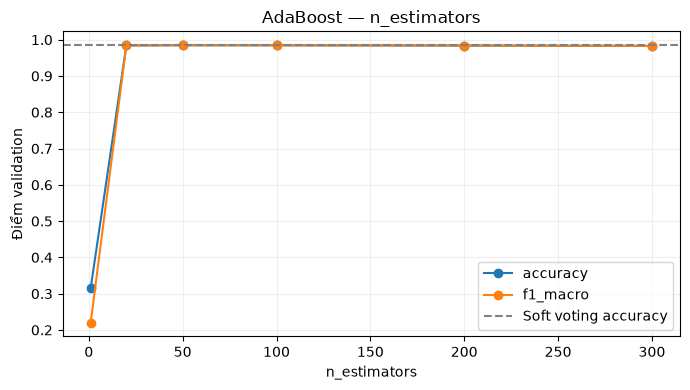

In [9]:
tree_counts = [1, 20, 50, 100, 200, 300]
model = make_meta(trees=300)
start = time.perf_counter(); model.fit(Z_train, y_train)
meta_search_fit_s += time.perf_counter() - start
tree_rows = [score_row(pred, 0.5, 2, trees) for trees, pred in enumerate(model.staged_predict(Z_val), 1) if trees in tree_counts]
tree_results = pd.DataFrame(tree_rows)
show_results(tree_results, 'n_estimators')

### 6.4. Chốt cấu hình

Chọn trong các cấu hình đã thử theo accuracy validation, F1 macro; nếu hòa ưu tiên cây nông, ít cây rồi learning rate nhỏ. Fit lại cấu hình đó trên OOF và đo thời gian fit cuối.

In [10]:
survey = pd.concat([lr_results, depth_results, tree_results], ignore_index=True).drop_duplicates(['learning_rate', 'max_depth', 'n_estimators'])
ranked = survey.sort_values(['accuracy', 'f1_macro', 'max_depth', 'n_estimators', 'learning_rate'], ascending=[False, False, True, True, True])
best = ranked.iloc[0]
meta = make_meta(float(best.learning_rate), int(best.max_depth), int(best.n_estimators))
start = time.perf_counter(); meta.fit(Z_train, y_train)
meta_fit_s = time.perf_counter() - start
display(ranked.round(5))
print('Cấu hình adaboost cuối:', meta)

,learning_rate,max_depth,n_estimators,accuracy,f1_macro
2,0.20,2.0,100.0,0.9853,0.98524
11,0.50,2.0,50.0,0.9848,0.98472
7,0.50,3.0,100.0,0.9848,0.98468
3,0.50,2.0,100.0,0.9846,0.98454
5,0.50,1.0,100.0,0.9844,0.98432
10,0.50,2.0,20.0,0.9841,0.98406
13,0.50,2.0,200.0,0.9839,0.98382
1,0.10,2.0,100.0,0.9834,0.98334
14,0.50,2.0,300.0,0.9828,0.98269
8,0.50,4.0,100.0,0.9827,0.98252


Cấu hình adaboost cuối: AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2,
                                                    random_state=42),
                   learning_rate=0.2, n_estimators=100, random_state=42)


**Giới hạn:** validation đã dùng để chọn nhóm ở 05 và chọn trọng số/tham số ở 06 nên điểm có thể lạc quan. Stacking không được bảo đảm thắng mô hình đơn hoặc voting; test chỉ đánh giá sau khi chốt lựa chọn.

## 7. Đánh giá và thời gian dự đoán

Báo cáo accuracy, precision/recall/F1 macro trên train, validation và test. Train là điểm in-sample của pipeline sau refit, không phải đánh giá độc lập hay điểm OOF.

Thời gian dự đoán mô hình đơn gồm tạo xác suất và argmax; voting/stacking gồm tạo xác suất các thành viên và bước gộp/meta. Các phương án dùng lại cùng lượt đo, chưa phải benchmark độc lập. Trọng số voting được giữ cố định sau khi chọn trên validation.

In [11]:
def evaluate(y, predictions, split):
    rows = []
    for name, pred in predictions.items():
        precision, recall, f1, _ = precision_recall_fscore_support(y, pred, labels=CLASSES, average='macro', zero_division=0)
        rows.append(dict(model=name, split=split, accuracy=accuracy_score(y, pred),
                         precision_macro=precision, recall_macro=recall, f1_macro=f1))
    return pd.DataFrame(rows)

recorded_stack_fit_s = oof_times.recorded_fold_seconds.sum() + base_times.recorded_fit_seconds.sum() + meta_fit_s
all_results, prediction_times, saved_predictions = [], [], {}
for split, X_split, y_split in [('Train', X_train, y_train), ('Validation', X_val, y_val), ('Test', X_test, y_test)]:
    if split == 'Validation':
        probabilities, predictions, timing_rows = val_proba, dict(val_pred), val_times
    else:
        probabilities, predictions, timing_rows = predict_bases(X_split)
    proba_s = sum(row['proba_seconds'] for row in timing_rows)
    start = time.perf_counter()
    Z = np.concatenate([probabilities[name] for name in names], axis=1)
    predictions['Stacking AdaBoost'] = meta.predict(Z)
    stacking_extra_s = time.perf_counter() - start
    start = time.perf_counter()
    predictions['Soft voting'] = np.mean([probabilities[name] for name in names], axis=0).argmax(1)
    voting_extra_s = time.perf_counter() - start
    start = time.perf_counter()
    predictions['Weighted soft voting'] = np.average(
        [probabilities[name] for name in names], axis=0, weights=voting_weights).argmax(1)
    weighted_extra_s = time.perf_counter() - start
    table = evaluate(y_split, predictions, split)
    fit_times = dict(zip(base_times.model, base_times.recorded_fit_seconds))
    fit_times.update({'Soft voting': base_times.recorded_fit_seconds.sum(),
                      'Weighted soft voting': base_times.recorded_fit_seconds.sum(), 'Stacking AdaBoost': recorded_stack_fit_s})
    predict_times = {row['model']: row['predict_seconds'] for row in timing_rows}
    predict_times.update({'Soft voting': proba_s+voting_extra_s,
                          'Weighted soft voting': proba_s+weighted_extra_s, 'Stacking AdaBoost': proba_s+stacking_extra_s})
    table['fit_seconds'] = table.model.map(fit_times)
    table['predict_seconds'] = table.model.map(predict_times)
    all_results.append(table); saved_predictions[split] = predictions
    prediction_times.extend([dict(split=split, **row) for row in timing_rows])
results = pd.concat(all_results, ignore_index=True)
display(results.round(5))
test_results = results[results.split == 'Test']
stack_acc = float(test_results.loc[test_results.model == 'Stacking AdaBoost', 'accuracy'].iloc[0])
best_single_acc = float(test_results.loc[test_results.model == best_single_name, 'accuracy'].iloc[0])
print(f'Stacking test accuracy={stack_acc:.2%}; chênh {best_single_name} (chọn bằng validation): {(stack_acc-best_single_acc)*100:+.2f} điểm phần trăm')

voting_comparison = results[results.model.isin(['Soft voting', 'Weighted soft voting', 'Stacking AdaBoost'])]
display(voting_comparison[['model', 'split', 'accuracy', 'f1_macro', 'predict_seconds']].round(5))

,model,split,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds
0,SVM,Train,0.99990,0.99990,0.99990,0.99990,942.40321,270.98737
1,KNN,Train,1.00000,1.00000,1.00000,1.00000,0.03381,17.05625
2,MLP256_128,Train,0.99990,0.99990,0.99990,0.99990,474.68422,0.23650
3,Stacking AdaBoost,Train,0.99998,0.99998,0.99998,0.99998,6513.24132,289.05112
4,Soft voting,Train,1.00000,1.00000,1.00000,1.00000,1417.12124,288.28611
5,Weighted soft voting,Train,1.00000,1.00000,1.00000,1.00000,1417.12124,288.28607
6,SVM,Validation,0.98330,0.98323,0.98322,0.98321,942.40321,55.10198
7,KNN,Validation,0.97200,0.97255,0.97163,0.97196,0.03381,3.65956
8,MLP256_128,Validation,0.98190,0.98177,0.98187,0.98180,474.68422,0.12128
9,Stacking AdaBoost,Validation,0.98530,0.98523,0.98526,0.98524,6513.24132,58.99412


Stacking test accuracy=98.54%; chênh SVM (chọn bằng validation): +0.21 điểm phần trăm


,model,split,accuracy,f1_macro,predict_seconds
3,Stacking AdaBoost,Train,0.99998,0.99998,289.05112
4,Soft voting,Train,1.00000,1.00000,288.28611
5,Weighted soft voting,Train,1.00000,1.00000,288.28607
9,Stacking AdaBoost,Validation,0.98530,0.98524,58.99412
10,Soft voting,Validation,0.98520,0.98515,58.88295
11,Weighted soft voting,Validation,0.98520,0.98515,58.88416
15,Stacking AdaBoost,Test,0.98540,0.98536,50.71464
16,Soft voting,Test,0.98520,0.98516,50.62710
17,Weighted soft voting,Test,0.98520,0.98516,50.62761


### Lỗi được sửa và tạo thêm lỗi

Trên test, so stacking với mô hình đơn tốt nhất đã chọn bằng validation và soft voting. Đếm lỗi sửa đúng, lỗi tạo thêm và chênh lệch.

In [12]:
stack_correct = saved_predictions['Test']['Stacking AdaBoost'] == y_test
error_rows = []
for name in [best_single_name, 'Soft voting']:
    ref_correct = saved_predictions['Test'][name] == y_test
    fixed = int((~ref_correct & stack_correct).sum())
    broken = int((ref_correct & ~stack_correct).sum())
    error_rows.append(dict(reference=name, corrected_errors=fixed,
                           introduced_errors=broken, net_errors_reduced=fixed-broken))
error_analysis = pd.DataFrame(error_rows)
display(error_analysis)

,reference,corrected_errors,introduced_errors,net_errors_reduced
0,SVM,40,19,21
1,Soft voting,20,18,2


## 8. Trực quan kết quả

Vẽ confusion matrix stacking trên ba tập, so sánh accuracy/F1 test và lập báo cáo theo chữ số.

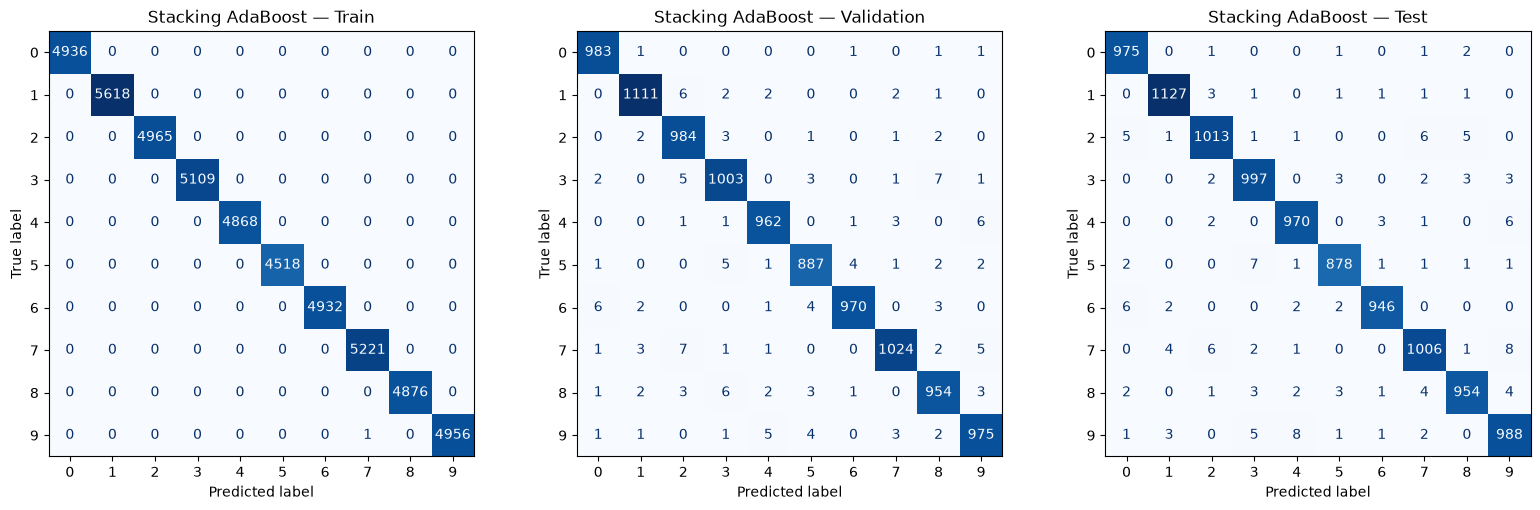

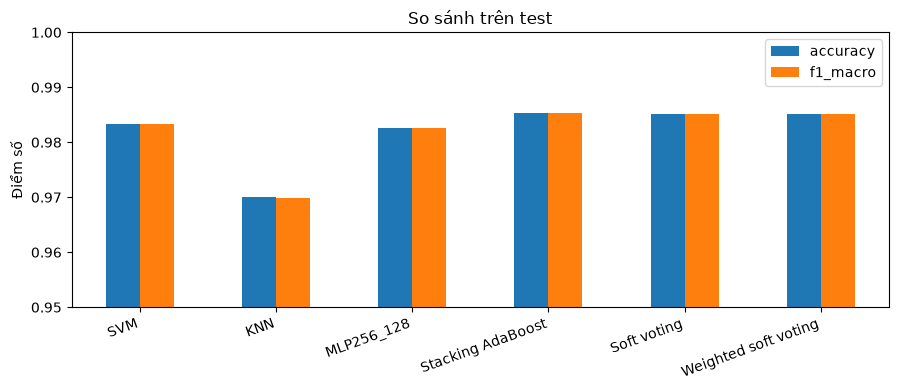

,precision,recall,f1-score,support
0,0.9839,0.9949,0.9893,980.0
1,0.9912,0.9930,0.9921,1135.0
2,0.9854,0.9816,0.9835,1032.0
3,0.9813,0.9871,0.9842,1010.0
4,0.9848,0.9878,0.9863,982.0
5,0.9876,0.9843,0.9860,892.0
6,0.9927,0.9875,0.9901,958.0
7,0.9824,0.9786,0.9805,1028.0
8,0.9866,0.9795,0.9830,974.0
9,0.9782,0.9792,0.9787,1009.0


In [15]:
datasets = {'Train': y_train, 'Validation': y_val, 'Test': y_test}
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (split, target) in zip(axes, datasets.items()):
    ConfusionMatrixDisplay.from_predictions(target, saved_predictions[split]['Stacking AdaBoost'], labels=CLASSES, ax=ax,
        cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'Stacking AdaBoost — {split}')
fig.tight_layout(); fig.savefig(OUTPUT / 'confusion_matrices.png', dpi=300); plt.show()
ax = test_results.set_index('model')[['accuracy', 'f1_macro']].plot.bar(figsize=(9, 4), ylim=(0, 1))
ax.set(xlabel='', ylabel='Điểm số', title='So sánh trên test')
plt.xticks(rotation=20, ha='right'); ax.figure.tight_layout()
ax.figure.savefig(OUTPUT / 'comparison_test.png', dpi=300)
ax.set_ylim(0.95, 1.0)
plt.show()
report = pd.DataFrame(classification_report(y_test, saved_predictions['Test']['Stacking AdaBoost'], output_dict=True, zero_division=0)).T
display(report.loc[[str(k) for k in CLASSES]].round(4))

## 9. Lưu kết quả và bộ phân lớp

Lưu bảng độ đo, khảo sát tham số, phân tích lỗi, thời gian, đặc trưng OOF/validation, split và bộ phân lớp tại `results/stacking_adaboost/`.

Chi phí fit stacking gồm các fold OOF, refit mô hình nền và fit meta cuối; chưa gồm khảo sát tham số. Khi bật cache, thời gian ghi trong fold có thể thuộc lần chạy trước; wall time phản ánh lần chạy hiện tại.

`classifier.joblib` giữ mô hình nền đã fit, AdaBoost, trọng số voting và thứ tự mô hình/lớp. Suy luận stacking: lấy xác suất → ghép đúng thứ tự → `meta.predict`. Chạy lại ghi đè các file cùng tên.

In [16]:
error_analysis.to_csv(OUTPUT / 'error_analysis_test.csv', index=False)
single_val.to_csv(OUTPUT / 'single_model_validation.csv', index=False)
results.to_csv(OUTPUT / 'metrics.csv', index=False)
results.query("model == 'Stacking AdaBoost' and split == 'Test'").to_csv(OUTPUT / 'comparison.csv', index=False)
weight_results.to_csv(OUTPUT / 'weighted_voting_search.csv', index=False)
weight_results.iloc[[best_weight_index]].to_csv(OUTPUT / 'weighted_voting_selected.csv', index=False)
voting_comparison.to_csv(OUTPUT / 'voting_stacking_comparison.csv', index=False)
survey.to_csv(OUTPUT / 'hyperparameters.csv', index=False)
ranked.head(1).to_csv(OUTPUT / 'selected_config.csv', index=False)
oof_times.to_csv(OUTPUT / 'oof_times.csv', index=False)
base_times.to_csv(OUTPUT / 'base_times.csv', index=False)
pd.DataFrame(prediction_times).to_csv(OUTPUT / 'prediction_times.csv', index=False)
report.to_csv(OUTPUT / 'classification_report_test.csv')
for split, target in datasets.items():
    for name, pred in saved_predictions[split].items():
        cm = confusion_matrix(target, pred, labels=CLASSES)
        pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(OUTPUT / f'{name.replace(" ", "_")}_confusion_{split.lower()}.csv', index_label='true_digit')
np.savez_compressed(OUTPUT / 'meta_features.npz', Z_train=Z_train, y_train=y_train,
                    Z_val=Z_val, y_val=y_val, fold_id=fold_id)
np.savez_compressed(OUTPUT / 'split_indices.npz', train_idx=tr, val_idx=va, seed=SEED)
config = dict(selection_source='select_base_models/selection.json',
    group_selection='selected_models from notebook 05; candidate groups not searched',
    prediction_rule='argmax(predict_proba)', data_fingerprint=data_fingerprint,
    best_single_model=best_single_name, voting_weights=voting_weights.tolist(), voting_weight_model_order=names,
    weighted_voting_search_seconds=weight_search_s, weighted_voting_selection='validation accuracy, then macro F1; equal weights first on ties',
    seed=SEED, folds=N_FOLDS, model_order=names, classes=CLASSES.tolist(), cache_enabled=USE_CACHE,
    learning_rate=float(best.learning_rate), max_depth=int(best.max_depth), n_estimators=int(best.n_estimators),
    actual_estimators=len(meta.estimators_), oof_wall_seconds=oof_wall_s, refit_wall_seconds=refit_wall_s,
    pipeline_training_wall_seconds=oof_wall_s + refit_wall_s + meta_fit_s,
    recorded_stack_fit_seconds=float(recorded_stack_fit_s), meta_search_fit_seconds=meta_search_fit_s,
    meta_final_fit_seconds=meta_fit_s, sklearn_version=sklearn.__version__)
(OUTPUT / 'config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
dump(dict(voting_weights=voting_weights, base_models=fitted, meta_model=meta, model_order=names, classes=CLASSES, seed=SEED, folds=N_FOLDS), OUTPUT / 'classifier.joblib')
print('Đã lưu:', OUTPUT)

Đã lưu: d:\Nhận dạng mẫu\mnist\results\stacking_adaboost
